# Determinants of Depression among University Students
### An Econometric Analysis using Logit and Probit Models

This notebook runs the complete analysis behind the research report. Every table, chart and
number used in the report, the Excel workbook and the appendix is produced by the cells below.

**Data:** `data/student_sample_300.csv` — survey responses of 300 university students aged 18–24.

**Outcome:** `Depression` (Yes / No).

**Structure**
1. Setup
2. Data overview and quality checks
3. Data transformation and variable coding
4. Descriptive analysis (tables and charts)
5. Bivariate tests (chi-square, t-test, Mann–Whitney)
6. Multicollinearity check (VIF)
7. Binary logit model, odds ratios and marginal effects
8. Binary probit model and marginal effects
9. Goodness of fit and diagnostics
10. Hypothesis testing summary
11. Robustness checks
12. Export of all results (CSV, Excel, JSON)

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "student_sample_300.csv"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
OUT = ROOT / "results" / "model_output"
for folder in (FIG, TAB, OUT):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Chart style: one blue for single series, blue/orange for No/Yes, muted text and grid.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
STATUS_COLORS = {"No": BLUE, "Yes": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False,
})

R = {}  # scalar results used in the report text


def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()


def bar_label(ax, bar, text):
    """Label inside the top of tall bars (white), above short bars (dark), so it never crosses reference lines."""
    x, h = bar.get_x() + bar.get_width() / 2, bar.get_height()
    if h >= 12:
        ax.text(x, h - 1.2, text, ha="center", va="top", fontsize=8.5, color="white", fontweight="bold")
    else:
        ax.text(x, h + 1, text, ha="center", va="bottom", fontsize=8.5, color=INK)


def save_table(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index)
    return df

## 2. Data overview and quality checks

In [2]:
raw = pd.read_csv(DATA)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (300, 13)


,Student_ID,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression
0,1,Female,23,Middle class,Single,Unmarried,Family,4,2.92,No,Good,7400,No
1,2,Male,20,Lower Middle class,Single,Unmarried,Bachelor,5,3.10,Yes,Normal,5896,No
2,3,Male,20,Middle class,Single,Unmarried,Bachelor,5,3.59,Yes,Abnormal,14815,Yes
3,4,Male,23,Middle class,In a Relationship,Unmarried,Family,2,3.00,Yes,Normal,19681,No
4,5,Male,22,Middle class,In a Relationship,Unmarried,Family,3,3.00,Yes,Normal,15750,No


In [3]:
quality = pd.DataFrame({
    "Column": raw.columns,
    "Type": raw.dtypes.astype(str).values,
    "Missing": raw.isna().sum().values,
    "Unique values": raw.nunique().values,
})
print("Duplicate rows:", raw.drop(columns="Student_ID").duplicated().sum())
save_table(quality, "data_quality")

Duplicate rows: 0


,Column,Type,Missing,Unique values
0,Student_ID,int64,0,300
1,Gender,object,0,2
2,Age,int64,0,7
3,Family_background,object,0,3
4,Relationship_status,object,0,3
5,Marital_status,object,0,3
6,Living_style,object,0,2
7,Current_semester,int64,0,12
8,CGPA,float64,0,90
9,friend_circle,object,0,2


In [4]:
preview = raw.head(5).copy()
save_table(preview, "raw_data_preview")

R["n"] = int(len(raw))
R["n_depressed"] = int((raw["Depression"] == "Yes").sum())
R["n_not_depressed"] = int((raw["Depression"] == "No").sum())
R["pct_depressed"] = round(100 * R["n_depressed"] / R["n"], 1)
R["n_male"] = int((raw["Gender"] == "Male").sum())
R["n_female"] = int((raw["Gender"] == "Female").sum())
R["age_min"], R["age_max"] = int(raw["Age"].min()), int(raw["Age"].max())
R["missing_total"] = int(raw.isna().sum().sum())
R["duplicates"] = int(raw.drop(columns="Student_ID").duplicated().sum())
R

{'n': 300,
 'n_depressed': 89,
 'n_not_depressed': 211,
 'pct_depressed': 29.7,
 'n_male': 144,
 'n_female': 156,
 'age_min': 18,
 'age_max': 24,
 'missing_total': 0,
 'duplicates': 0}

## 3. Data transformation and variable coding

Text answers are converted to numbers so they can enter the regression models.

* **Binary (0/1) variables:** depression, gender (male = 1), living with family, friend circle.
* **Family background:** dummies for *Lower middle class* and *Rich class*; *Middle class* is the base group.
* **Relationship status:** *Complicated* has only 11 students and none of them is depressed, so it is
  merged with *In a relationship* — the variable becomes **Single (1) vs Not single (0)**.
* **Marital status:** *Separated* has only 6 students, so it is merged with *Married* — **Ever married (1)**.
* **Monthly cost (excluding study costs)** is expressed in thousands of local currency units.
* **Health condition** is kept for descriptive analysis. It is *not* used in the main model because it
  separates the outcome almost perfectly (checked in Section 4).

In [5]:
d = pd.DataFrame({"student_id": raw["Student_ID"]})
d["depression"] = (raw["Depression"] == "Yes").astype(int)
d["male"] = (raw["Gender"] == "Male").astype(int)
d["age"] = raw["Age"]
d["cgpa"] = raw["CGPA"]
d["semester"] = raw["Current_semester"]
d["cost_k"] = raw["Cost_without_study"] / 1000
d["fam_lowermid"] = (raw["Family_background"] == "Lower Middle class").astype(int)
d["fam_rich"] = (raw["Family_background"] == "Rich class").astype(int)
d["single"] = (raw["Relationship_status"] == "Single").astype(int)
d["ever_married"] = raw["Marital_status"].isin(["Married", "Separated"]).astype(int)
d["live_family"] = (raw["Living_style"] == "Family").astype(int)
d["friend_circle"] = (raw["friend_circle"] == "Yes").astype(int)
d["health_poor"] = raw["Health_condition"].isin(["Abnormal", "Critical"]).astype(int)
d["health_level"] = raw["Health_condition"].map({"Good": 1, "Normal": 2, "Abnormal": 3, "Critical": 4})
d.head()

,student_id,depression,male,age,cgpa,semester,cost_k,fam_lowermid,fam_rich,single,ever_married,live_family,friend_circle,health_poor,health_level
0,1,0,0,23,2.92,4,7.400,0,0,1,0,1,0,0,1
1,2,0,1,20,3.10,5,5.896,1,0,1,0,0,1,0,2
2,3,1,1,20,3.59,5,14.815,0,0,1,0,0,1,1,3
3,4,0,1,23,3.00,2,19.681,0,0,0,0,1,1,0,2
4,5,0,1,22,3.00,3,15.750,0,0,0,0,1,1,0,2


In [6]:
LABELS = {
    "depression": "Depression",
    "male": "Male",
    "age": "Age (years)",
    "cgpa": "CGPA",
    "semester": "Current semester",
    "cost_k": "Monthly cost ('000)",
    "fam_lowermid": "Lower-middle class",
    "fam_rich": "Rich class",
    "single": "Single",
    "ever_married": "Ever married",
    "live_family": "Lives with family",
    "friend_circle": "Has friend circle",
    "health_poor": "Poor health",
    "health_level": "Health level (1-4)",
}

dictionary = pd.DataFrame([
    ["depression", "Depression", "Whether the student reports depression. 1 = Yes, 0 = No.", "Binary (dependent variable)"],
    ["male", "Gender", "Gender of the student. 1 = Male, 0 = Female.", "Binary"],
    ["age", "Age", "Age of the student in years (18-24).", "Numerical (discrete)"],
    ["cgpa", "CGPA", "Cumulative grade point average on a 4.00 scale.", "Numerical (continuous)"],
    ["semester", "Current semester", "Semester the student is currently in.", "Numerical (discrete)"],
    ["cost_k", "Monthly cost", "Monthly living cost excluding study costs, in thousands of local currency units.", "Numerical (continuous)"],
    ["fam_lowermid", "Family background", "1 = Lower-middle class family (base group: middle class).", "Binary (dummy)"],
    ["fam_rich", "Family background", "1 = Rich class family (base group: middle class).", "Binary (dummy)"],
    ["single", "Relationship status", "1 = Single, 0 = In a relationship or complicated.", "Binary"],
    ["ever_married", "Marital status", "1 = Married or separated, 0 = Unmarried.", "Binary"],
    ["live_family", "Living style", "1 = Lives with family, 0 = Lives as a bachelor (hostel/mess/shared).", "Binary"],
    ["friend_circle", "Friend circle", "1 = Has a friend circle, 0 = Does not.", "Binary"],
    ["health_poor", "Health condition", "1 = Abnormal or critical health, 0 = Good or normal (robustness model only).", "Binary"],
    ["health_level", "Health condition", "1 = Good, 2 = Normal, 3 = Abnormal, 4 = Critical (descriptive only).", "Ordinal"],
], columns=["Variable", "Survey question", "Description and coding", "Data type"])
save_table(dictionary, "variable_dictionary")
d.to_csv(TAB / "coded_data.csv", index=False)
dictionary

,Variable,Survey question,Description and coding,Data type
0,depression,Depression,Whether the student reports depression. 1 = Ye...,Binary (dependent variable)
1,male,Gender,"Gender of the student. 1 = Male, 0 = Female.",Binary
2,age,Age,Age of the student in years (18-24).,Numerical (discrete)
3,cgpa,CGPA,Cumulative grade point average on a 4.00 scale.,Numerical (continuous)
4,semester,Current semester,Semester the student is currently in.,Numerical (discrete)
5,cost_k,Monthly cost,"Monthly living cost excluding study costs, in ...",Numerical (continuous)
6,fam_lowermid,Family background,1 = Lower-middle class family (base group: mid...,Binary (dummy)
7,fam_rich,Family background,1 = Rich class family (base group: middle class).,Binary (dummy)
8,single,Relationship status,"1 = Single, 0 = In a relationship or complicated.",Binary
9,ever_married,Marital status,"1 = Married or separated, 0 = Unmarried.",Binary


## 4. Descriptive analysis
### 4.1 Summary statistics (equivalent to Stata `summarize`)

In [7]:
NUMERIC = ["depression", "male", "age", "cgpa", "semester", "cost_k", "fam_lowermid", "fam_rich",
           "single", "ever_married", "live_family", "friend_circle", "health_poor"]
summary = pd.DataFrame({
    "Variable": [LABELS[v] for v in NUMERIC],
    "Obs": [int(d[v].count()) for v in NUMERIC],
    "Mean": [d[v].mean() for v in NUMERIC],
    "Std. dev.": [d[v].std() for v in NUMERIC],
    "Min": [d[v].min() for v in NUMERIC],
    "Max": [d[v].max() for v in NUMERIC],
}).round(3)
save_table(summary, "summary_statistics")
summary

,Variable,Obs,Mean,Std. dev.,Min,Max
0,Depression,300,0.297,0.458,0.000,1.0
1,Male,300,0.480,0.500,0.000,1.0
2,Age (years),300,21.677,1.409,18.000,24.0
3,CGPA,300,3.486,0.352,2.500,4.0
4,Current semester,300,5.193,2.204,0.000,11.0
5,Monthly cost ('000),300,13.398,6.182,0.342,32.0
6,Lower-middle class,300,0.190,0.393,0.000,1.0
7,Rich class,300,0.167,0.373,0.000,1.0
8,Single,300,0.640,0.481,0.000,1.0
9,Ever married,300,0.150,0.358,0.000,1.0


In [8]:
by_status = d.groupby("depression")[["age", "cgpa", "semester", "cost_k"]].agg(["mean", "std"]).round(3)
by_status.index = ["Not depressed", "Depressed"]
by_status

age          cgpa        semester         cost_k       
                 mean    std   mean    std     mean    std    mean    std
Not depressed  21.678  1.387  3.475  0.354    5.256  2.289  12.961  6.042
Depressed      21.674  1.468  3.513  0.349    5.045  1.994  14.434  6.418

### 4.2 Depression in the sample (equivalent to Stata `tabulate depression`)

In [9]:
tab_dep = raw["Depression"].value_counts().reindex(["No", "Yes"]).rename_axis("Depression").reset_index(name="Freq.")
tab_dep["Percent"] = (100 * tab_dep["Freq."] / tab_dep["Freq."].sum()).round(2)
tab_dep["Cum."] = tab_dep["Percent"].cumsum().round(2)
save_table(tab_dep, "tabulate_depression")
tab_dep

,Depression,Freq.,Percent,Cum.
0,No,211,70.33,70.33
1,Yes,89,29.67,100.00


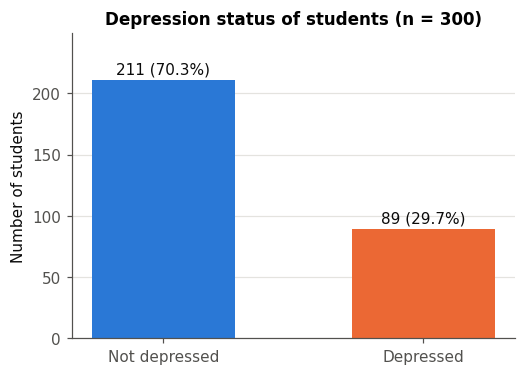

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
bars = ax.bar(["Not depressed", "Depressed"], tab_dep["Freq."], color=[BLUE, ORANGE], width=0.55)
for bar, n, pct in zip(bars, tab_dep["Freq."], tab_dep["Percent"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3, f"{n} ({pct:.1f}%)",
            ha="center", va="bottom", color=INK)
ax.set_ylabel("Number of students")
ax.set_title("Depression status of students (n = 300)")
ax.set_ylim(0, tab_dep["Freq."].max() * 1.18)
ax.grid(axis="x", visible=False)
save_fig(fig, "fig01_depression_distribution")

### 4.3 Depression rate by student characteristics

In [11]:
GROUP_VARS = {
    "Gender": ["Female", "Male"],
    "Family_background": ["Lower Middle class", "Middle class", "Rich class"],
    "Relationship_status": ["Single", "In a Relationship", "Complicated"],
    "Marital_status": ["Unmarried", "Married", "Separated"],
    "Living_style": ["Bachelor", "Family"],
    "friend_circle": ["No", "Yes"],
    "Health_condition": ["Good", "Normal", "Abnormal", "Critical"],
}
NICE = {"Gender": "Gender", "Family_background": "Family background", "Relationship_status": "Relationship status",
        "Marital_status": "Marital status", "Living_style": "Living style", "friend_circle": "Friend circle",
        "Health_condition": "Health condition"}

rows = []
for var, levels in GROUP_VARS.items():
    for level in levels:
        grp = raw[raw[var] == level]
        rows.append([NICE[var], level, len(grp), int((grp["Depression"] == "Yes").sum()),
                     round(100 * (grp["Depression"] == "Yes").mean(), 1)])
rates = pd.DataFrame(rows, columns=["Characteristic", "Group", "Students", "Depressed", "Depression rate (%)"])
save_table(rates, "depression_rates_by_group")
rates

,Characteristic,Group,Students,Depressed,Depression rate (%)
0,Gender,Female,156,43,27.6
1,Gender,Male,144,46,31.9
2,Family background,Lower Middle class,57,11,19.3
3,Family background,Middle class,193,69,35.8
4,Family background,Rich class,50,9,18.0
5,Relationship status,Single,192,81,42.2
6,Relationship status,In a Relationship,97,8,8.2
7,Relationship status,Complicated,11,0,0.0
8,Marital status,Unmarried,255,80,31.4
9,Marital status,Married,39,8,20.5


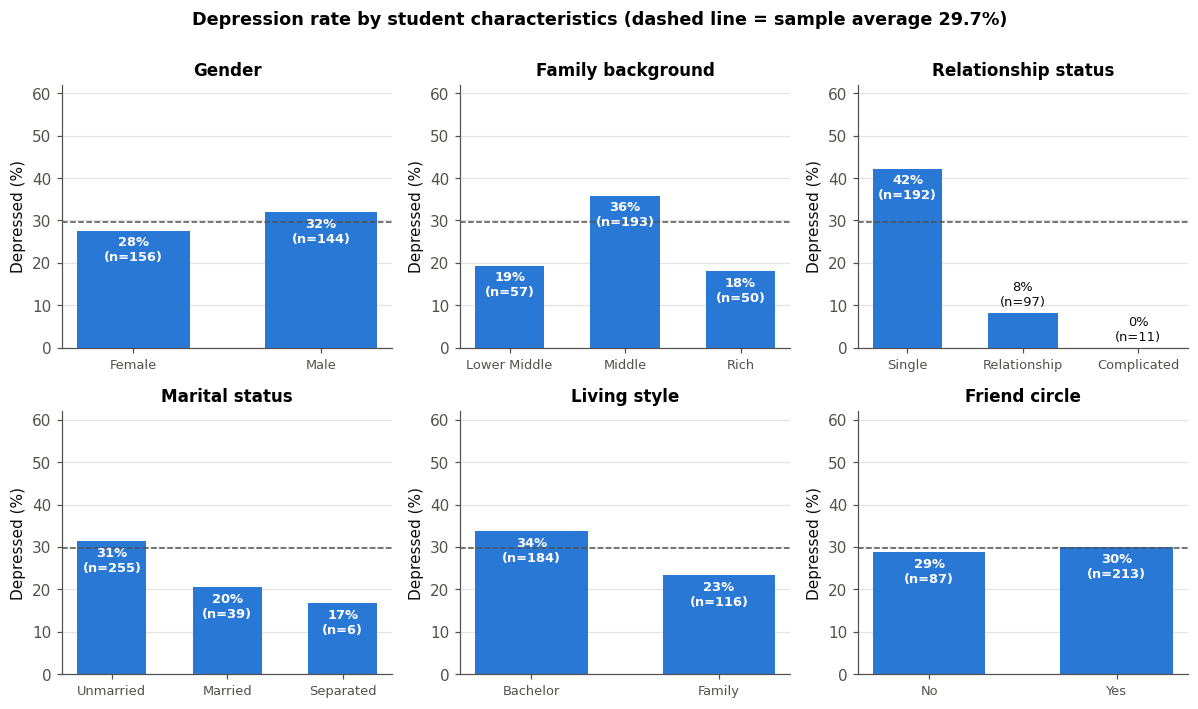

In [12]:
overall = 100 * d["depression"].mean()
panels = ["Gender", "Family_background", "Relationship_status", "Marital_status", "Living_style", "friend_circle"]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
for ax, var in zip(axes.ravel(), panels):
    sub = rates[rates["Characteristic"] == NICE[var]]
    bars = ax.bar(sub["Group"].str.replace(" class", "").str.replace("In a ", ""), sub["Depression rate (%)"],
                  color=BLUE, width=0.6)
    for bar, rate, n in zip(bars, sub["Depression rate (%)"], sub["Students"]):
        bar_label(ax, bar, f"{rate:.0f}%\n(n={n})")
    ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(NICE[var])
    ax.set_ylim(0, 62)
    ax.set_ylabel("Depressed (%)")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8.5)
fig.suptitle(f"Depression rate by student characteristics (dashed line = sample average {overall:.1f}%)",
             fontsize=11.5, fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "fig02_rates_by_group")

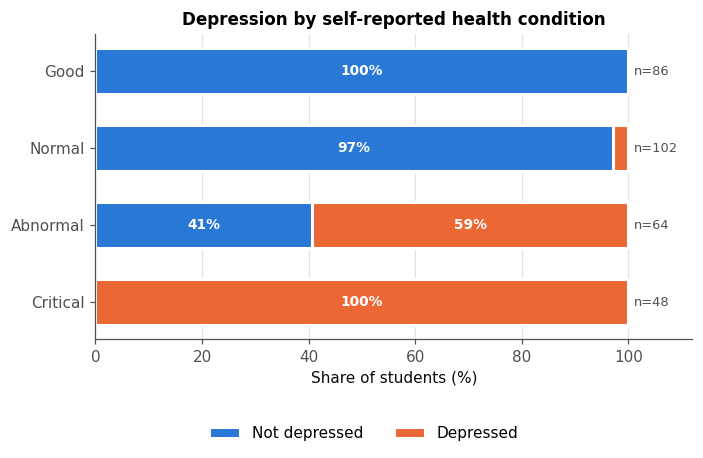

Depression,No,Yes
Health_condition,,
Good,86,0
Normal,99,3
Abnormal,26,38
Critical,0,48


In [13]:
hc = pd.crosstab(raw["Health_condition"], raw["Depression"]).reindex(["Good", "Normal", "Abnormal", "Critical"])
hc_pct = hc.div(hc.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(7, 3.6))
left = np.zeros(len(hc_pct))
for status in ["No", "Yes"]:
    ax.barh(hc_pct.index, hc_pct[status], left=left, color=STATUS_COLORS[status], height=0.6,
            edgecolor="white", linewidth=2, label="Not depressed" if status == "No" else "Depressed")
    for i, (val, start) in enumerate(zip(hc_pct[status], left)):
        if val >= 6:
            ax.text(start + val / 2, i, f"{val:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += hc_pct[status].values
for i, total in enumerate(hc.sum(axis=1)):
    ax.text(101, i, f"n={total}", va="center", fontsize=8.5, color=MUTED)
ax.set_xlim(0, 112)
ax.invert_yaxis()
ax.set_xlabel("Share of students (%)")
ax.set_title("Depression by self-reported health condition")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.38), ncol=2)
ax.grid(axis="y", visible=False)
save_fig(fig, "fig03_health_condition")

R["health_critical_rate"] = float(hc_pct.loc["Critical", "Yes"].round(1))
R["health_good_rate"] = float(hc_pct.loc["Good", "Yes"].round(1))
R["health_normal_rate"] = float(hc_pct.loc["Normal", "Yes"].round(1))
R["health_abnormal_rate"] = float(hc_pct.loc["Abnormal", "Yes"].round(1))
hc

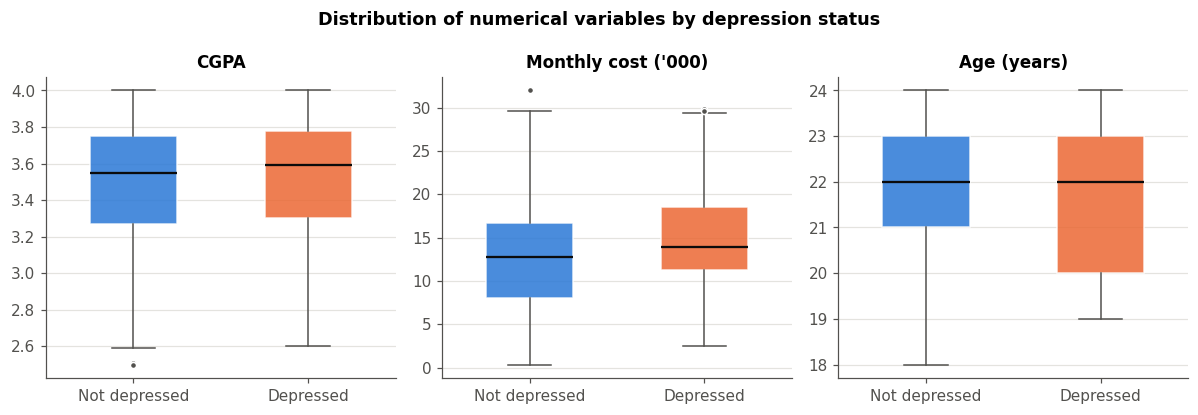

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (var, title) in zip(axes, [("cgpa", "CGPA"), ("cost_k", "Monthly cost ('000)"), ("age", "Age (years)")]):
    groups = [d.loc[d["depression"] == 0, var], d.loc[d["depression"] == 1, var]]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.5, medianprops={"color": INK, "linewidth": 1.5},
                    whiskerprops={"color": MUTED}, capprops={"color": MUTED},
                    flierprops={"marker": "o", "markersize": 4, "markerfacecolor": MUTED, "markeredgecolor": "white"})
    for patch, color in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(color)
        patch.set_edgecolor("white")
        patch.set_alpha(0.85)
    ax.set_xticks([1, 2], ["Not depressed", "Depressed"])
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of numerical variables by depression status", fontsize=11.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig04_numeric_by_depression")

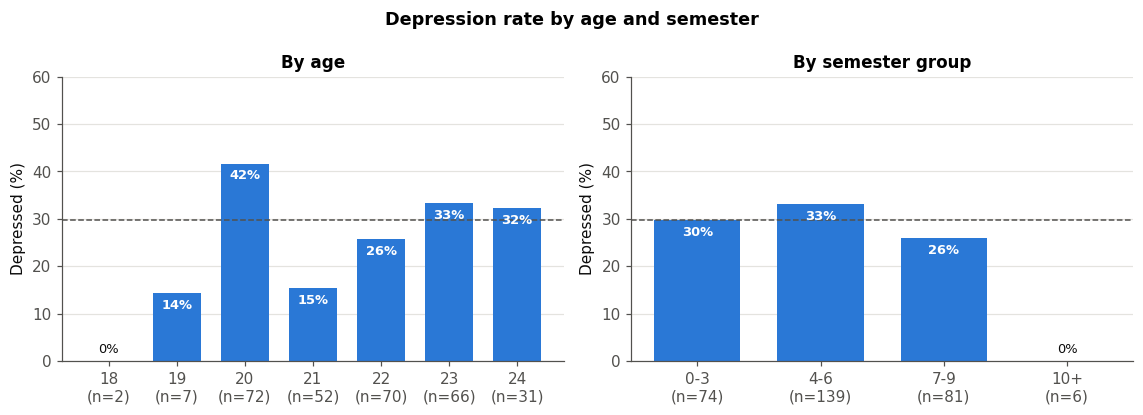

In [15]:
age_rates = d.groupby("age")["depression"].agg(["size", "mean"]).reset_index()
d["semester_group"] = pd.cut(d["semester"], bins=[-1, 3, 6, 9, 20], labels=["0-3", "4-6", "7-9", "10+"])
sem_rates = d.groupby("semester_group", observed=True)["depression"].agg(["size", "mean"]).reset_index()
save_table(age_rates.rename(columns={"size": "Students", "mean": "Depression rate"}), "depression_rate_by_age")
save_table(sem_rates.rename(columns={"size": "Students", "mean": "Depression rate"}), "depression_rate_by_semester")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, tbl, key, title in [(axes[0], age_rates, "age", "By age"), (axes[1], sem_rates, "semester_group", "By semester group")]:
    tick_labels = [f"{k}\n(n={n})" for k, n in zip(tbl[key].astype(str), tbl["size"])]
    bars = ax.bar(tick_labels, 100 * tbl["mean"], color=BLUE, width=0.7)
    for bar, rate in zip(bars, 100 * tbl["mean"]):
        bar_label(ax, bar, f"{rate:.0f}%")
    ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_ylim(0, 60)
    ax.set_ylabel("Depressed (%)")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
fig.suptitle("Depression rate by age and semester", fontsize=11.5, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig05_rate_by_age_semester")

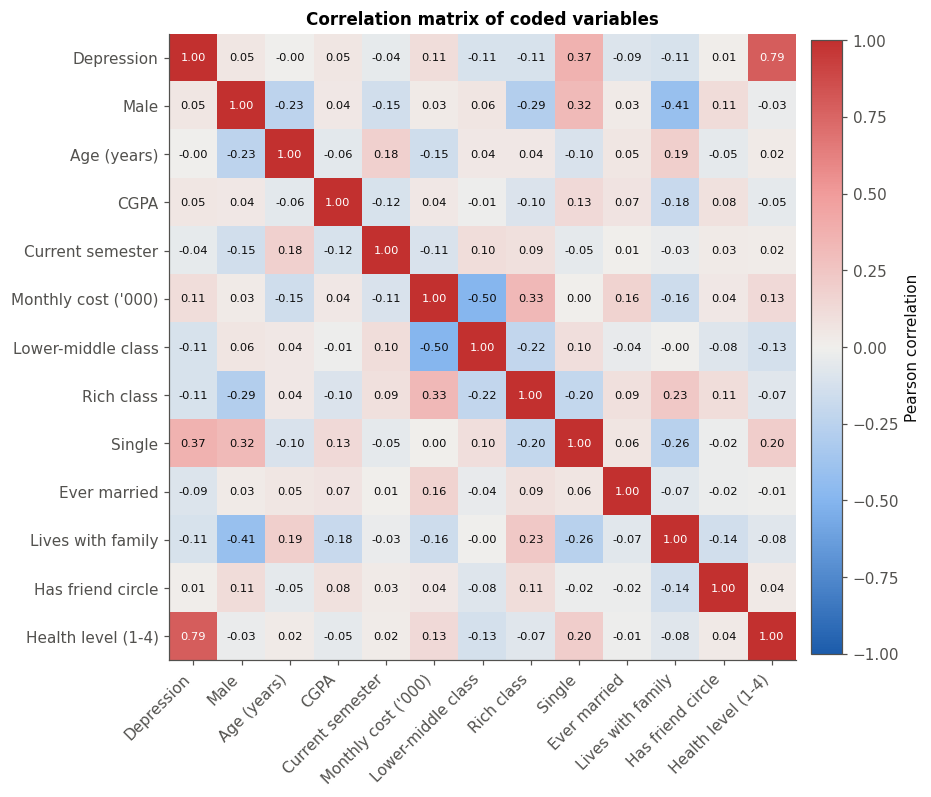

In [16]:
from matplotlib.colors import LinearSegmentedColormap

CORR_VARS = ["depression", "male", "age", "cgpa", "semester", "cost_k", "fam_lowermid", "fam_rich",
             "single", "ever_married", "live_family", "friend_circle", "health_level"]
corr = d[CORR_VARS].corr()
save_table(corr.round(3).rename(index=LABELS, columns=LABELS), "correlation_matrix", index=True)

diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f19c9b", "#c2302f"])
fig, ax = plt.subplots(figsize=(9, 7.4))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_VARS)), [LABELS[v] for v in CORR_VARS], rotation=45, ha="right")
ax.set_yticks(range(len(CORR_VARS)), [LABELS[v] for v in CORR_VARS])
for i in range(len(CORR_VARS)):
    for j in range(len(CORR_VARS)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(val) > 0.55 else INK)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="Pearson correlation")
ax.set_title("Correlation matrix of coded variables")
save_fig(fig, "fig06_correlation_matrix")

## 5. Bivariate tests
### 5.1 Chi-square tests of independence (categorical variables vs depression)

In [17]:
def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


chi_rows = []
for var in GROUP_VARS:
    table = pd.crosstab(raw[var], raw["Depression"])
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    row = [NICE[var], round(chi2, 3), dof, p, round(cramers_v(table), 3), round(expected.min(), 2)]
    row.append(stats.fisher_exact(table.values)[1] if table.shape == (2, 2) else np.nan)
    chi_rows.append(row)
chi_tests = pd.DataFrame(chi_rows, columns=["Variable", "Chi-square", "df", "p-value", "Cramer's V",
                                            "Min expected count", "Fisher exact p (2x2)"])
save_table(chi_tests, "chi_square_tests")
chi_tests

,Variable,Chi-square,df,p-value,Cramer's V,Min expected count,Fisher exact p (2x2)
0,Gender,0.689,1,4.066491e-01,0.048,42.72,0.448633
1,Family background,9.623,2,8.136133e-03,0.179,14.83,NaN
2,Relationship status,40.394,2,1.692994e-09,0.367,3.26,NaN
3,Marital status,2.408,2,3.000238e-01,0.090,1.78,NaN
4,Living style,3.702,1,5.434558e-02,0.111,34.41,0.068935
5,Friend circle,0.051,1,8.214955e-01,0.013,25.81,0.889617
6,Health condition,212.060,3,1.044859e-45,0.841,14.24,NaN


### 5.2 Difference in means (numerical variables): Welch t-test and Mann–Whitney U test

In [18]:
t_rows = []
for var in ["cgpa", "cost_k", "age", "semester"]:
    a, b = d.loc[d["depression"] == 0, var], d.loc[d["depression"] == 1, var]
    t, p_t = stats.ttest_ind(b, a, equal_var=False)
    u, p_u = stats.mannwhitneyu(b, a, alternative="two-sided")
    t_rows.append([LABELS[var], a.mean(), b.mean(), b.mean() - a.mean(), t, p_t, u, p_u])
t_tests = pd.DataFrame(t_rows, columns=["Variable", "Mean (not depressed)", "Mean (depressed)", "Difference",
                                        "Welch t", "t-test p-value", "Mann-Whitney U", "Mann-Whitney p-value"]).round(4)
save_table(t_tests, "t_tests")
t_tests

,Variable,Mean (not depressed),Mean (depressed),Difference,Welch t,t-test p-value,Mann-Whitney U,Mann-Whitney p-value
0,CGPA,3.4751,3.5134,0.0383,0.8653,0.3881,10211.5,0.2311
1,Monthly cost ('000),12.9605,14.4338,1.4732,1.8476,0.0665,10726.5,0.0515
2,Age (years),21.6777,21.6742,-0.0036,-0.0195,0.9844,9312.0,0.9087
3,Current semester,5.2559,5.0449,-0.2110,-0.8003,0.4245,9060.5,0.6280


## 6. Multicollinearity check (Variance Inflation Factor)

In [19]:
MAIN = ["male", "age", "cgpa", "semester", "cost_k", "fam_lowermid", "fam_rich",
        "single", "ever_married", "live_family", "friend_circle"]
y = d["depression"]
X = sm.add_constant(d[MAIN].astype(float))
vif = pd.DataFrame({
    "Variable": [LABELS[v] for v in MAIN],
    "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
}).round(3)
vif["Tolerance (1/VIF)"] = (1 / vif["VIF"]).round(3)
save_table(vif, "vif")
R["vif_max"] = float(vif["VIF"].max())
vif

,Variable,VIF,Tolerance (1/VIF)
0,Male,1.410,0.709
1,Age (years),1.127,0.887
2,CGPA,1.077,0.929
3,Current semester,1.110,0.901
4,Monthly cost ('000),1.614,0.620
5,Lower-middle class,1.378,0.726
6,Rich class,1.371,0.729
7,Single,1.176,0.850
8,Ever married,1.053,0.950
9,Lives with family,1.405,0.712


## 7. Binary logit model

$$\Pr(\text{Depression}_i = 1) = \Lambda(\beta_0 + \beta_1\,\text{Male}_i + \beta_2\,\text{Age}_i + \beta_3\,\text{CGPA}_i
+ \beta_4\,\text{Semester}_i + \beta_5\,\text{Cost}_i + \beta_6\,\text{LowerMid}_i + \beta_7\,\text{Rich}_i
+ \beta_8\,\text{Single}_i + \beta_9\,\text{EverMarried}_i + \beta_{10}\,\text{LiveFamily}_i + \beta_{11}\,\text{FriendCircle}_i)$$

where $\Lambda(z) = e^z / (1 + e^z)$. Stata equivalent: `logit depression male age cgpa semester cost_k i.fam_lowermid ...`

In [20]:
logit = sm.Logit(y, X).fit(disp=0)
print(logit.summary())
(OUT / "logit_summary.txt").write_text(logit.summary().as_text())


def coef_table(res, labels=LABELS):
    ci = res.conf_int()
    table = pd.DataFrame({
        "Variable": ["Constant" if v == "const" else labels[v] for v in res.params.index],
        "Coefficient": res.params.values,
        "Std. err.": res.bse.values,
        "z": res.tvalues.values,
        "P>|z|": res.pvalues.values,
        "95% CI lower": ci[0].values,
        "95% CI upper": ci[1].values,
    })
    return table


def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


logit_table = coef_table(logit)
logit_table["Sig."] = logit_table["P>|z|"].apply(stars)
save_table(logit_table.round(4), "logit_coefficients")
logit_table.round(4)

                           Logit Regression Results                           
Dep. Variable:             depression   No. Observations:                  300
Model:                          Logit   Df Residuals:                      288
Method:                           MLE   Df Model:                           11
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                  0.1907
Time:                        16:44:00   Log-Likelihood:                -147.62
converged:                       True   LL-Null:                       -182.40
Covariance Type:            nonrobust   LLR p-value:                 1.474e-10
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -5.1987      2.917     -1.782      0.075     -10.916       0.519
male             -0.6574      0.347     -1.894      0.058      -1.338       0.023
age               0.1244      0.106     

,Variable,Coefficient,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Constant,-5.1987,2.9172,-1.7821,0.0747,-10.9163,0.5190,*
1,Male,-0.6574,0.3472,-1.8936,0.0583,-1.3378,0.0230,*
2,Age (years),0.1244,0.1061,1.1727,0.2409,-0.0835,0.3324,
3,CGPA,-0.0885,0.4290,-0.2062,0.8366,-0.9292,0.7523,
4,Current semester,-0.0373,0.0718,-0.5188,0.6039,-0.1781,0.1035,
5,Monthly cost ('000),0.0699,0.0357,1.9584,0.0502,-0.0001,0.1398,*
6,Lower-middle class,-0.7071,0.4649,-1.5210,0.1283,-1.6183,0.2041,
7,Rich class,-1.2038,0.5899,-2.0405,0.0413,-2.3600,-0.0475,**
8,Single,2.5285,0.4285,5.9005,0.0000,1.6886,3.3684,***
9,Ever married,-1.1145,0.4516,-2.4681,0.0136,-1.9995,-0.2295,**


### 7.1 Odds ratios (Stata: `logit ..., or`)

In [21]:
or_table = pd.DataFrame({
    "Variable": logit_table["Variable"],
    "Odds ratio": np.exp(logit.params.values),
    "95% CI lower": np.exp(logit.conf_int()[0].values),
    "95% CI upper": np.exp(logit.conf_int()[1].values),
    "P>|z|": logit.pvalues.values,
}).round(4)
or_table["Sig."] = or_table["P>|z|"].apply(stars)
save_table(or_table, "logit_odds_ratios")
or_table

,Variable,Odds ratio,95% CI lower,95% CI upper,P>|z|,Sig.
0,Constant,0.0055,0.0000,1.6803,0.0747,*
1,Male,0.5182,0.2624,1.0233,0.0583,*
2,Age (years),1.1325,0.9199,1.3943,0.2409,
3,CGPA,0.9153,0.3949,2.1220,0.8366,
4,Current semester,0.9634,0.8369,1.1091,0.6039,
5,Monthly cost ('000),1.0724,0.9999,1.1500,0.0502,*
6,Lower-middle class,0.4931,0.1982,1.2264,0.1283,
7,Rich class,0.3001,0.0944,0.9536,0.0413,**
8,Single,12.5349,5.4120,29.0327,0.0000,***
9,Ever married,0.3281,0.1354,0.7950,0.0136,**


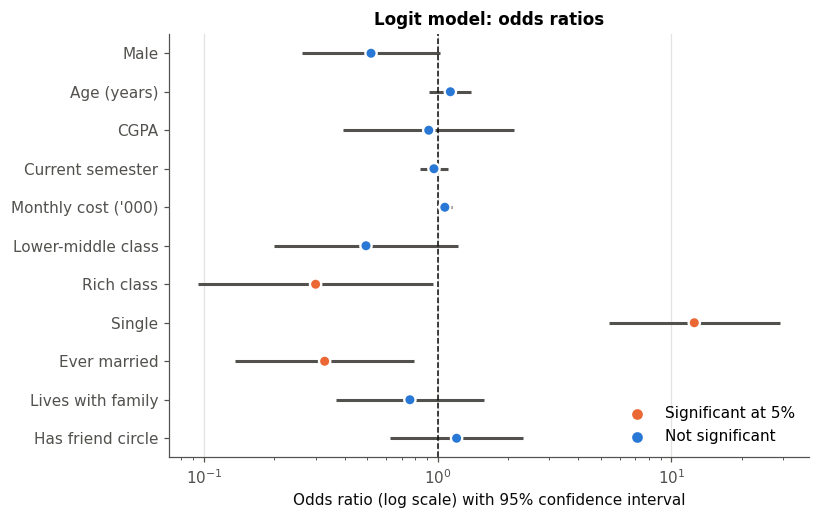

In [22]:
plot_or = or_table[or_table["Variable"] != "Constant"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
sig = plot_or["P>|z|"] < 0.05
ax.hlines(range(len(plot_or)), plot_or["95% CI lower"], plot_or["95% CI upper"], color=MUTED, linewidth=2)
ax.scatter(plot_or["Odds ratio"], range(len(plot_or)), s=55, zorder=3,
           color=[ORANGE if s else BLUE for s in sig], edgecolor="white", linewidth=1.5)
ax.axvline(1, color=INK, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_yticks(range(len(plot_or)), plot_or["Variable"])
ax.set_xlabel("Odds ratio (log scale) with 95% confidence interval")
ax.set_title("Logit model: odds ratios")
ax.scatter([], [], color=ORANGE, label="Significant at 5%")
ax.scatter([], [], color=BLUE, label="Not significant")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig07_logit_odds_ratios")

### 7.2 Marginal effects after logit
**Average marginal effects (AME)** — Stata: `margins, dydx(*)`. For 0/1 variables the effect is the discrete change
from 0 to 1. **Marginal effects at the means (MEM)** — Stata: `margins, dydx(*) atmeans` (older `mfx`).

In [23]:
def margeff_table(res, at):
    frame = res.get_margeff(at=at, dummy=True).summary_frame()
    frame.index = [LABELS[v] for v in frame.index]
    frame = frame.reset_index().rename(columns={"index": "Variable", "dy/dx": "dy/dx", "Std. Err.": "Std. err.",
                                                "Pr(>|z|)": "P>|z|", "Conf. Int. Low": "95% CI lower",
                                                "Cont. Int. Hi.": "95% CI upper"})
    frame["Sig."] = frame["P>|z|"].apply(stars)
    return frame.round(4)


logit_ame = margeff_table(logit, "overall")
logit_mem = margeff_table(logit, "mean")
save_table(logit_ame, "logit_marginal_effects_ame")
save_table(logit_mem, "logit_marginal_effects_mem")
R["logit_pred_at_means"] = float(logit.predict(X.mean().to_frame().T)[0])
print("Predicted probability of depression at the means:", round(R["logit_pred_at_means"], 4))
logit_ame

Predicted probability of depression at the means: 0.2243


,Variable,dy/dx,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Male,-0.1070,0.0545,-1.9633,0.0496,-0.2139,-0.0002,**
1,Age (years),0.0205,0.0174,1.1825,0.2370,-0.0135,0.0546,
2,CGPA,-0.0146,0.0708,-0.2062,0.8366,-0.1533,0.1241,
3,Current semester,-0.0061,0.0118,-0.5196,0.6033,-0.0293,0.0170,
4,Monthly cost ('000),0.0115,0.0058,2.0042,0.0451,0.0003,0.0228,**
5,Lower-middle class,-0.1118,0.0685,-1.6335,0.1024,-0.2460,0.0224,
6,Rich class,-0.1716,0.0671,-2.5587,0.0105,-0.3030,-0.0401,**
7,Single,0.3643,0.0425,8.5802,0.0000,0.2811,0.4475,***
8,Ever married,-0.1643,0.0557,-2.9497,0.0032,-0.2735,-0.0551,***
9,Lives with family,-0.0448,0.0600,-0.7468,0.4552,-0.1623,0.0727,


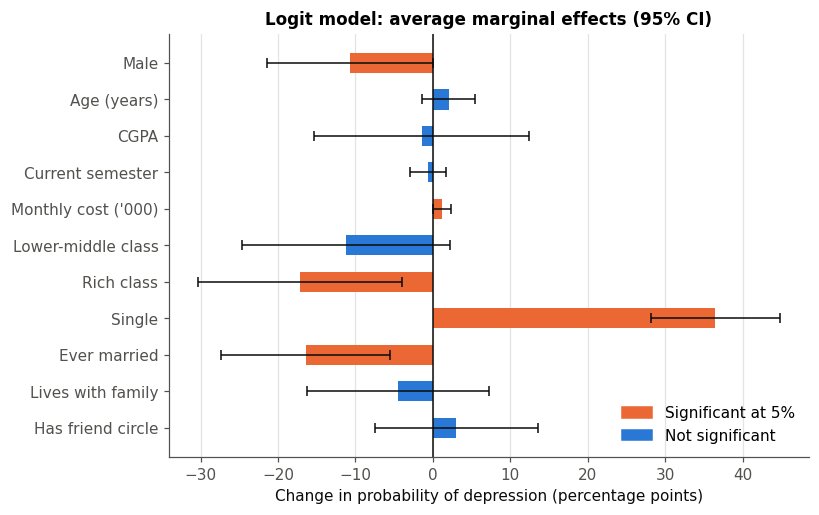

In [24]:
plot_me = logit_ame.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
sig = plot_me["P>|z|"] < 0.05
ax.barh(plot_me["Variable"], 100 * plot_me["dy/dx"], color=[ORANGE if s else BLUE for s in sig], height=0.55)
ax.errorbar(100 * plot_me["dy/dx"], range(len(plot_me)),
            xerr=[100 * (plot_me["dy/dx"] - plot_me["95% CI lower"]), 100 * (plot_me["95% CI upper"] - plot_me["dy/dx"])],
            fmt="none", ecolor=INK, elinewidth=1, capsize=3)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel("Change in probability of depression (percentage points)")
ax.set_title("Logit model: average marginal effects (95% CI)")
ax.legend(handles=[Patch(color=ORANGE, label="Significant at 5%"), Patch(color=BLUE, label="Not significant")],
          loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig08_logit_marginal_effects")

## 8. Binary probit model
$$\Pr(\text{Depression}_i = 1) = \Phi(\mathbf{x}_i'\boldsymbol\beta)$$ where $\Phi$ is the standard normal CDF.
Stata equivalent: `probit depression ...` followed by `margins, dydx(*)`.

In [25]:
probit = sm.Probit(y, X).fit(disp=0)
print(probit.summary())
(OUT / "probit_summary.txt").write_text(probit.summary().as_text())
probit_table = coef_table(probit)
probit_table["Sig."] = probit_table["P>|z|"].apply(stars)
save_table(probit_table.round(4), "probit_coefficients")
probit_table.round(4)

                          Probit Regression Results                           
Dep. Variable:             depression   No. Observations:                  300
Model:                         Probit   Df Residuals:                      288
Method:                           MLE   Df Model:                           11
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                  0.1915
Time:                        16:44:01   Log-Likelihood:                -147.47
converged:                       True   LL-Null:                       -182.40
Covariance Type:            nonrobust   LLR p-value:                 1.296e-10
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -3.0986      1.744     -1.777      0.076      -6.517       0.319
male             -0.4204      0.204     -2.058      0.040      -0.821      -0.020
age               0.0673      0.063     

,Variable,Coefficient,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Constant,-3.0986,1.7439,-1.7769,0.0756,-6.5166,0.3193,*
1,Male,-0.4204,0.2043,-2.0578,0.0396,-0.8207,-0.0200,**
2,Age (years),0.0673,0.0630,1.0681,0.2855,-0.0562,0.1907,
3,CGPA,-0.0210,0.2538,-0.0828,0.9340,-0.5185,0.4765,
4,Current semester,-0.0159,0.0418,-0.3810,0.7032,-0.0978,0.0659,
5,Monthly cost ('000),0.0436,0.0209,2.0833,0.0372,0.0026,0.0847,**
6,Lower-middle class,-0.3983,0.2750,-1.4486,0.1475,-0.9373,0.1406,
7,Rich class,-0.7000,0.3404,-2.0566,0.0397,-1.3671,-0.0329,**
8,Single,1.4643,0.2306,6.3495,0.0000,1.0123,1.9163,***
9,Ever married,-0.5894,0.2532,-2.3278,0.0199,-1.0856,-0.0931,**


In [26]:
probit_ame = margeff_table(probit, "overall")
probit_mem = margeff_table(probit, "mean")
save_table(probit_ame, "probit_marginal_effects_ame")
save_table(probit_mem, "probit_marginal_effects_mem")
R["probit_pred_at_means"] = float(probit.predict(X.mean().to_frame().T)[0])
probit_ame

,Variable,dy/dx,Std. err.,z,P>|z|,95% CI lower,95% CI upper,Sig.
0,Male,-0.1149,0.0537,-2.1397,0.0324,-0.2201,-0.0096,**
1,Age (years),0.0187,0.0174,1.0731,0.2832,-0.0154,0.0527,
2,CGPA,-0.0058,0.0704,-0.0828,0.9340,-0.1439,0.1322,
3,Current semester,-0.0044,0.0116,-0.3810,0.7032,-0.0271,0.0183,
4,Monthly cost ('000),0.0121,0.0057,2.1320,0.0330,0.0010,0.0232,**
5,Lower-middle class,-0.1060,0.0689,-1.5387,0.1239,-0.2411,0.0290,
6,Rich class,-0.1706,0.0680,-2.5074,0.0122,-0.3039,-0.0372,**
7,Single,0.3676,0.0426,8.6251,0.0000,0.2841,0.4512,***
8,Ever married,-0.1487,0.0560,-2.6560,0.0079,-0.2584,-0.0390,***
9,Lives with family,-0.0437,0.0582,-0.7499,0.4533,-0.1578,0.0705,


## 9. Goodness of fit and diagnostics

In [27]:
def hosmer_lemeshow(y_true, p_hat, groups=10):
    frame = pd.DataFrame({"y": y_true, "p": p_hat})
    frame["g"] = pd.qcut(frame["p"], groups, duplicates="drop")
    g = frame.groupby("g", observed=True).agg(obs=("y", "sum"), exp=("p", "sum"), n=("y", "size"))
    hl = (((g["obs"] - g["exp"]) ** 2) / (g["exp"] * (1 - g["exp"] / g["n"]))).sum()
    dof = len(g) - 2
    return hl, dof, 1 - stats.chi2.cdf(hl, dof)


def classification(y_true, p_hat, cutoff=0.5):
    pred = (p_hat >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"Cutoff": cutoff, "True positives": tp, "False positives": fp, "False negatives": fn,
            "True negatives": tn, "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
            "Correctly classified": (tp + tn) / len(y_true)}


fit_rows, class_rows = [], []
for name, res in [("Logit", logit), ("Probit", probit)]:
    p_hat = res.predict(X)
    hl, hl_df, hl_p = hosmer_lemeshow(y, p_hat)
    fit_rows.append({"Model": name, "Observations": int(res.nobs), "Log likelihood": res.llf,
                     "Log likelihood (null)": res.llnull, "LR chi2": res.llr, "LR df": int(res.df_model),
                     "Prob > chi2": res.llr_pvalue, "Pseudo R2 (McFadden)": res.prsquared,
                     "AIC": res.aic, "BIC": res.bic, "AUC (ROC)": roc_auc_score(y, p_hat),
                     "Hosmer-Lemeshow chi2": hl, "HL df": hl_df, "HL p-value": hl_p})
    for cut in (0.5, y.mean()):
        class_rows.append({"Model": name, **classification(y, p_hat, cut)})
fit_stats = pd.DataFrame(fit_rows).round(4)
class_table = pd.DataFrame(class_rows).round(4)
save_table(fit_stats, "model_fit_statistics")
save_table(class_table, "classification_tables")
fit_stats.T

,0,1
Model,Logit,Probit
Observations,300,300
Log likelihood,-147.6186,-147.4713
Log likelihood (null),-182.404,-182.404
LR chi2,69.5708,69.8655
LR df,11,11
Prob > chi2,0.0,0.0
Pseudo R2 (McFadden),0.1907,0.1915
AIC,319.2373,318.9426
BIC,363.6827,363.388


In [28]:
class_table

,Model,Cutoff,True positives,False positives,False negatives,True negatives,Sensitivity,Specificity,Correctly classified
0,Logit,0.5000,39,30,50,181,0.4382,0.8578,0.7333
1,Logit,0.2967,71,73,18,138,0.7978,0.6540,0.6967
2,Probit,0.5000,37,28,52,183,0.4157,0.8673,0.7333
3,Probit,0.2967,74,74,15,137,0.8315,0.6493,0.7033


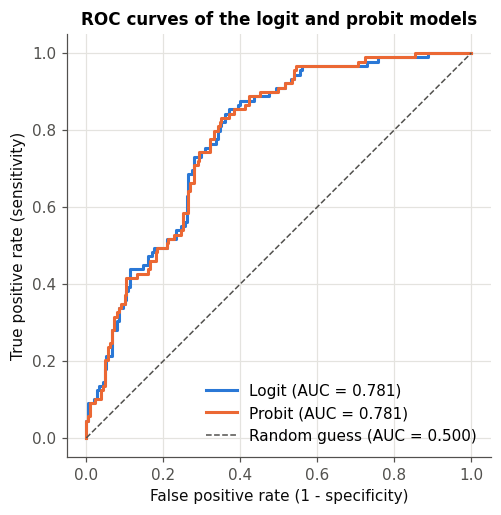

In [29]:
fig, ax = plt.subplots(figsize=(5.6, 5))
roc_points = []
for name, res, color in [("Logit", logit, BLUE), ("Probit", probit, ORANGE)]:
    fpr, tpr, _ = roc_curve(y, res.predict(X))
    roc_points += [{"Model": name, "False positive rate": a, "True positive rate": b} for a, b in zip(fpr, tpr)]
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y, res.predict(X)):.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random guess (AUC = 0.500)")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curves of the logit and probit models")
ax.legend(loc="lower right")
ax.set_aspect("equal")
save_table(pd.DataFrame(roc_points).round(4), "roc_curve_points")
save_fig(fig, "fig09_roc_curves")

### 9.1 Predicted probability profiles
Predicted probability of depression across CGPA, for single and not-single students, with all other variables at their means.

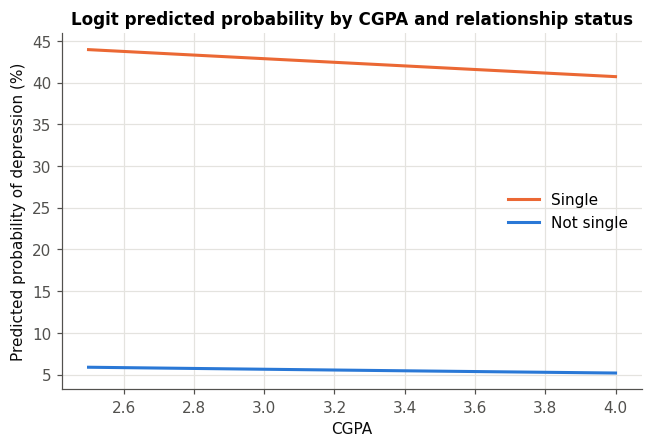

In [30]:
grid = np.linspace(d["cgpa"].min(), d["cgpa"].max(), 60)
fig, ax = plt.subplots(figsize=(6.8, 4.2))
profile_rows = []
for single, color, label in [(1, ORANGE, "Single"), (0, BLUE, "Not single")]:
    base = X.mean().to_frame().T.loc[np.repeat(0, len(grid))].reset_index(drop=True)
    base["cgpa"], base["single"] = grid, single
    p = logit.predict(base)
    ax.plot(grid, 100 * p, color=color, linewidth=2, label=label)
    profile_rows += [{"CGPA": g, "Single": single, "Predicted probability": v} for g, v in zip(grid, p)]
ax.set_xlabel("CGPA")
ax.set_ylabel("Predicted probability of depression (%)")
ax.set_title("Logit predicted probability by CGPA and relationship status")
ax.legend()
save_table(pd.DataFrame(profile_rows).round(4), "predicted_probability_profiles")
save_fig(fig, "fig10_predicted_probability_cgpa")

## 10. Hypothesis testing summary
Decision rule: a hypothesis is **supported** when the logit coefficient has the expected sign and p < 0.05.

In [31]:
HYPOTHESES = [
    ("H1", "Students with higher CGPA are less likely to be depressed (academic stress).", "cgpa", "-"),
    ("H2", "Students with a friend circle are less likely to be depressed (social support).", "friend_circle", "-"),
    ("H3", "Single students are more likely to be depressed than students in a relationship.", "single", "+"),
    ("H4a", "Students from lower-middle class families are more likely to be depressed than middle class.", "fam_lowermid", "+"),
    ("H4b", "Students from rich families are less likely to be depressed than middle class.", "fam_rich", "-"),
    ("H5", "Higher monthly living cost is associated with higher depression (financial pressure).", "cost_k", "+"),
    ("H6", "Students living with family are less likely to be depressed than those living as bachelors.", "live_family", "-"),
    ("H7", "Female students are more likely to be depressed than male students.", "male", "-"),
]
h_rows = []
for code, text, var, sign in HYPOTHESES:
    b, p = logit.params[var], logit.pvalues[var]
    ame = logit_ame.set_index("Variable").loc[LABELS[var], "dy/dx"]
    right_sign = (b < 0) if sign == "-" else (b > 0)
    if p < 0.05 and right_sign:
        verdict = "Supported"
    elif p < 0.05:
        verdict = "Rejected (significant, opposite sign)"
    elif p < 0.10 and right_sign:
        verdict = "Weakly supported (10% level)"
    else:
        verdict = "Not supported (not significant)"
    h_rows.append([code, text, LABELS[var], sign, round(b, 4), round(ame, 4), round(p, 4), verdict])
hyp = pd.DataFrame(h_rows, columns=["Hypothesis", "Statement", "Variable", "Expected sign", "Logit coefficient",
                                    "AME", "P>|z|", "Result"])
save_table(hyp, "hypothesis_tests")
hyp

,Hypothesis,Statement,Variable,Expected sign,Logit coefficient,AME,P>|z|,Result
0,H1,Students with higher CGPA are less likely to b...,CGPA,-,-0.0885,-0.0146,0.8366,Not supported (not significant)
1,H2,Students with a friend circle are less likely ...,Has friend circle,-,0.1859,0.0304,0.5760,Not supported (not significant)
2,H3,Single students are more likely to be depresse...,Single,+,2.5285,0.3643,0.0000,Supported
3,H4a,Students from lower-middle class families are ...,Lower-middle class,+,-0.7071,-0.1118,0.1283,Not supported (not significant)
4,H4b,Students from rich families are less likely to...,Rich class,-,-1.2038,-0.1716,0.0413,Supported
5,H5,Higher monthly living cost is associated with ...,Monthly cost ('000),+,0.0699,0.0115,0.0502,Weakly supported (10% level)
6,H6,Students living with family are less likely to...,Lives with family,-,-0.2743,-0.0448,0.4617,Not supported (not significant)
7,H7,Female students are more likely to be depresse...,Male,-,-0.6574,-0.1070,0.0583,Weakly supported (10% level)


## 11. Robustness checks
* **(1) Logit** — main model.
* **(2) Logit, robust SE** — heteroskedasticity-robust (HC1) standard errors (Stata: `vce(robust)`).
* **(3) Probit** — different link function.
* **(4) Linear probability model (LPM)** — OLS with robust SE (Stata: `regress ..., vce(robust)`).
* **(5) Logit + poor health** — adds the health indicator to show how strongly it dominates.
* **(6)/(7) Male and female students separately — linear probability model with robust SE.**
  A logit cannot be used here: among male students, none of the non-single students is depressed, so
  `single` predicts the outcome perfectly in the male subsample (quasi-complete separation) and its logit
  coefficient goes to infinity. The LPM is not affected by separation, so it is used for both subsamples.

In [32]:
logit_robust = sm.Logit(y, X).fit(disp=0, cov_type="HC1")
lpm = sm.OLS(y, X).fit(cov_type="HC1")
X_health = sm.add_constant(d[MAIN + ["health_poor"]].astype(float))
logit_health = sm.Logit(y, X_health).fit(disp=0, maxiter=200)
(OUT / "lpm_summary.txt").write_text(lpm.summary().as_text())
(OUT / "logit_robust_summary.txt").write_text(logit_robust.summary().as_text())
(OUT / "logit_health_summary.txt").write_text(logit_health.summary().as_text())

separation = pd.crosstab([raw["Gender"], raw["Relationship_status"] == "Single"], raw["Depression"])
separation.index = separation.index.set_names(["Gender", "Single"])
save_table(separation.reset_index(), "separation_check_gender_single")
print(separation)
R["male_not_single_n"] = int(separation.loc[("Male", False)].sum())
R["male_not_single_depressed"] = int(separation.loc[("Male", False), "Yes"])

sub_models = {}
for label, flag in [("Male students", 1), ("Female students", 0)]:
    sub = d[d["male"] == flag]
    Xs = sm.add_constant(sub[[v for v in MAIN if v != "male"]].astype(float))
    sub_models[label] = sm.OLS(sub["depression"], Xs).fit(cov_type="HC1")
    (OUT / f"lpm_{label.split()[0].lower()}_summary.txt").write_text(sub_models[label].summary().as_text())

models = {"(1) Logit": logit, "(2) Logit robust SE": logit_robust, "(3) Probit": probit, "(4) LPM robust SE": lpm,
          "(5) Logit + poor health": logit_health, "(6) LPM male": sub_models["Male students"],
          "(7) LPM female": sub_models["Female students"]}


def cell(res, var):
    if var not in res.params.index:
        return ""
    return f"{res.params[var]:.3f}{stars(res.pvalues[var])}\n({res.bse[var]:.3f})"


ALL_VARS = ["const"] + MAIN + ["health_poor"]
robust = pd.DataFrame({name: [cell(res, v) for v in ALL_VARS] for name, res in models.items()},
                      index=["Constant" if v == "const" else LABELS[v] for v in ALL_VARS])
footer = pd.DataFrame({name: [str(int(res.nobs)),
                              f"{res.prsquared:.3f}" if hasattr(res, "prsquared") else f"{res.rsquared:.3f}"]
                       for name, res in models.items()}, index=["Observations", "Pseudo R2 / R2"])
robust = pd.concat([robust, footer]).reset_index().rename(columns={"index": "Variable"})
save_table(robust, "robustness_models")
robust

Depression     No  Yes
Gender Single         
Female False   71    8
       True    42   35
Male   False   29    0
       True    69   46


,Variable,(1) Logit,(2) Logit robust SE,(3) Probit,(4) LPM robust SE,(5) Logit + poor health,(6) LPM male,(7) LPM female
0,Constant,-5.199*\n(2.917),-5.199*\n(2.757),-3.099*\n(1.744),-0.297\n(0.477),-7.915\n(6.957),-0.219\n(0.690),-0.521\n(0.752)
1,Male,-0.657*\n(0.347),-0.657*\n(0.340),-0.420**\n(0.204),-0.095*\n(0.057),-1.153\n(0.823),,
2,Age (years),0.124\n(0.106),0.124\n(0.104),0.067\n(0.063),0.018\n(0.019),-0.247\n(0.253),-0.004\n(0.029),0.045\n(0.030)
3,CGPA,-0.088\n(0.429),-0.088\n(0.432),-0.021\n(0.254),-0.011\n(0.070),1.477\n(1.016),0.097\n(0.123),-0.109\n(0.096)
4,Current semester,-0.037\n(0.072),-0.037\n(0.075),-0.016\n(0.042),-0.003\n(0.012),0.080\n(0.163),0.005\n(0.020),-0.013\n(0.015)
5,Monthly cost ('000),0.070*\n(0.036),0.070**\n(0.033),0.044**\n(0.021),0.009*\n(0.005),0.001\n(0.069),0.004\n(0.011),0.010*\n(0.005)
6,Lower-middle class,-0.707\n(0.465),-0.707\n(0.441),-0.398\n(0.275),-0.131*\n(0.068),-0.831\n(1.126),-0.234**\n(0.113),-0.013\n(0.099)
7,Rich class,-1.204**\n(0.590),-1.204**\n(0.511),-0.700**\n(0.340),-0.139**\n(0.061),0.868\n(1.053),-0.322**\n(0.159),-0.101\n(0.077)
8,Single,2.529***\n(0.429),2.529***\n(0.413),1.464***\n(0.231),0.376***\n(0.049),5.356***\n(1.004),0.390***\n(0.071),0.320***\n(0.070)
9,Ever married,-1.115**\n(0.452),-1.115**\n(0.505),-0.589**\n(0.253),-0.163**\n(0.071),-2.710***\n(1.045),-0.251***\n(0.093),-0.049\n(0.118)


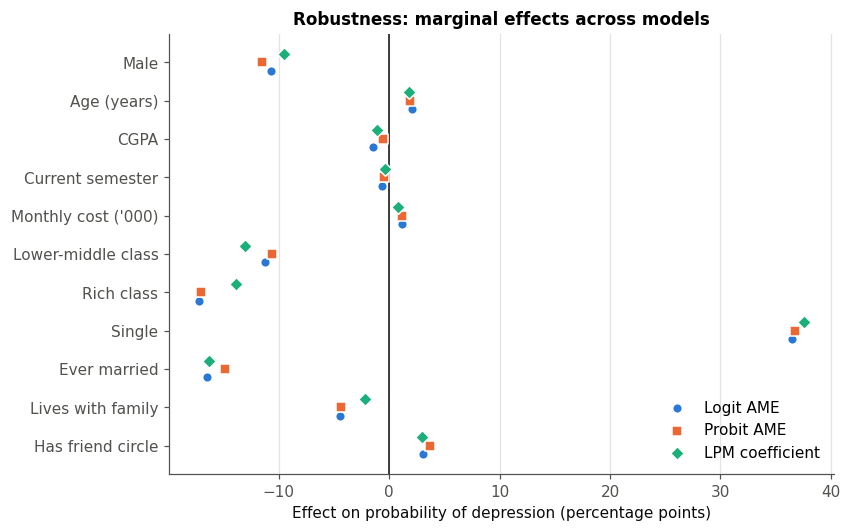

,Variable,Logit AME,Logit AME p,Probit AME,Probit AME p,LPM coefficient,LPM p (robust)
0,Male,-0.1070,0.0496,-0.1149,0.0324,-0.0952,0.0977
1,Age (years),0.0205,0.2370,0.0187,0.2832,0.0185,0.3192
2,CGPA,-0.0146,0.8366,-0.0058,0.9340,-0.0113,0.8715
3,Current semester,-0.0061,0.6033,-0.0044,0.7032,-0.0033,0.7762
4,Monthly cost ('000),0.0115,0.0451,0.0121,0.0330,0.0085,0.0685
5,Lower-middle class,-0.1118,0.1024,-0.1060,0.1239,-0.1307,0.0538
6,Rich class,-0.1716,0.0105,-0.1706,0.0122,-0.1387,0.0238
7,Single,0.3643,0.0000,0.3676,0.0000,0.3755,0.0000
8,Ever married,-0.1643,0.0032,-0.1487,0.0079,-0.1625,0.0219
9,Lives with family,-0.0448,0.4552,-0.0437,0.4533,-0.0219,0.7007


In [33]:
compare = pd.DataFrame({
    "Variable": logit_ame["Variable"],
    "Logit AME": logit_ame["dy/dx"].values,
    "Logit AME p": logit_ame["P>|z|"].values,
    "Probit AME": probit_ame["dy/dx"].values,
    "Probit AME p": probit_ame["P>|z|"].values,
    "LPM coefficient": lpm.params[MAIN].values,
    "LPM p (robust)": lpm.pvalues[MAIN].values,
}).round(4)
save_table(compare, "marginal_effects_comparison")

fig, ax = plt.subplots(figsize=(7.8, 5.2))
ypos = np.arange(len(compare))[::-1]
for offset, col, color, marker, label in [(-0.22, "Logit AME", BLUE, "o", "Logit AME"),
                                          (0, "Probit AME", ORANGE, "s", "Probit AME"),
                                          (0.22, "LPM coefficient", "#1baf7a", "D", "LPM coefficient")]:
    ax.scatter(100 * compare[col], ypos + offset, color=color, marker=marker, s=40, label=label,
               edgecolor="white", linewidth=1, zorder=3)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(ypos, compare["Variable"])
ax.set_xlabel("Effect on probability of depression (percentage points)")
ax.set_title("Robustness: marginal effects across models")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig11_robustness_comparison")
compare

In [34]:
sub_ame = []  # LPM coefficients are marginal effects directly
for label, res in sub_models.items():
    for var in res.params.index.drop("const"):
        sub_ame.append({"Sample": label, "Variable": LABELS[var], "dy/dx": res.params[var], "P>|z|": res.pvalues[var],
                        "Observations": int(res.nobs), "Depressed": int(res.model.endog.sum())})
sub_ame = pd.DataFrame(sub_ame).round(4)
save_table(sub_ame, "subsample_marginal_effects")
sub_ame.pivot(index="Variable", columns="Sample", values=["dy/dx", "P>|z|"])

dy/dx                         P>|z|              
Sample              Female students Male students Female students Male students
Variable                                                                       
Age (years)                  0.0453       -0.0040          0.1271        0.8910
CGPA                        -0.1085        0.0966          0.2579        0.4319
Current semester            -0.0133        0.0050          0.3827        0.8011
Ever married                -0.0485       -0.2512          0.6799        0.0068
Has friend circle            0.0126       -0.0045          0.8660        0.9576
Lives with family           -0.0276        0.0276          0.7065        0.7607
Lower-middle class          -0.0134       -0.2336          0.8927        0.0396
Monthly cost ('000)          0.0103        0.0041          0.0581        0.7096
Rich class                  -0.1006       -0.3216          0.1917        0.0435
Single                       0.3199        0.3902          0.0000        0.0000

In [35]:
lr_health = 2 * (logit_health.llf - logit.llf)
R["lr_health_chi2"] = float(lr_health)
R["lr_health_p"] = float(1 - stats.chi2.cdf(lr_health, 1))
R["health_model_pseudo_r2"] = float(logit_health.prsquared)
R["health_model_auc"] = float(roc_auc_score(y, logit_health.predict(X_health)))
print(f"Adding poor health: LR chi2 = {lr_health:.2f}, p = {R['lr_health_p']:.3g}, "
      f"pseudo R2 {logit.prsquared:.3f} -> {logit_health.prsquared:.3f}")

Adding poor health: LR chi2 = 218.82, p = 0, pseudo R2 0.191 -> 0.791


## 12. Export all results

In [36]:
R.update({
    "logit_ll": float(logit.llf), "logit_lr_chi2": float(logit.llr), "logit_lr_df": int(logit.df_model),
    "logit_lr_p": float(logit.llr_pvalue), "logit_pseudo_r2": float(logit.prsquared),
    "logit_aic": float(logit.aic), "logit_bic": float(logit.bic),
    "probit_ll": float(probit.llf), "probit_lr_chi2": float(probit.llr), "probit_lr_p": float(probit.llr_pvalue),
    "probit_pseudo_r2": float(probit.prsquared), "probit_aic": float(probit.aic), "probit_bic": float(probit.bic),
    "logit_auc": float(fit_stats.loc[0, "AUC (ROC)"]), "probit_auc": float(fit_stats.loc[1, "AUC (ROC)"]),
    "logit_hl_chi2": float(fit_stats.loc[0, "Hosmer-Lemeshow chi2"]), "logit_hl_p": float(fit_stats.loc[0, "HL p-value"]),
    "logit_correct_05": float(class_table.loc[0, "Correctly classified"]),
    "logit_sens_05": float(class_table.loc[0, "Sensitivity"]), "logit_spec_05": float(class_table.loc[0, "Specificity"]),
    "lpm_r2": float(lpm.rsquared),
})
(ROOT / "results" / "results.json").write_text(json.dumps(R, indent=2))
R

{'n': 300,
 'n_depressed': 89,
 'n_not_depressed': 211,
 'pct_depressed': 29.7,
 'n_male': 144,
 'n_female': 156,
 'age_min': 18,
 'age_max': 24,
 'missing_total': 0,
 'duplicates': 0,
 'health_critical_rate': 100.0,
 'health_good_rate': 0.0,
 'health_normal_rate': 2.9,
 'health_abnormal_rate': 59.4,
 'vif_max': 1.614,
 'logit_pred_at_means': 0.22432266162598966,
 'probit_pred_at_means': 0.23473409314377253,
 'male_not_single_n': 29,
 'male_not_single_depressed': 0,
 'lr_health_chi2': 218.82016106404853,
 'lr_health_p': 0.0,
 'health_model_pseudo_r2': 0.7905279011315602,
 'health_model_auc': 0.98647425315512,
 'logit_ll': -147.6186374972118,
 'logit_lr_chi2': 69.5708037099833,
 'logit_lr_df': 11,
 'logit_lr_p': 1.4740211763947708e-10,
 'logit_pseudo_r2': 0.19070521671849938,
 'logit_aic': 319.2372749944236,
 'logit_bic': 363.682664690298,
 'probit_ll': -147.47130065164185,
 'probit_lr_chi2': 69.86547737538922,
 'probit_lr_p': 1.2957544657033524e-10,
 'probit_pseudo_r2': 0.1915129665670

In [37]:
from openpyxl import load_workbook
from openpyxl.drawing.image import Image as XLImage
from openpyxl.styles import Alignment, Font, PatternFill

XLSX = ROOT / "results" / "Student_Depression_Analysis_Results.xlsx"
about = pd.DataFrame({"Item": ["Title", "Data", "Outcome", "Main models", "Software", "Sheets"],
                      "Details": ["Determinants of Depression among University Students",
                                  f"{R['n']} university students aged {R['age_min']}-{R['age_max']}",
                                  f"Depression (Yes = 1): {R['n_depressed']} students ({R['pct_depressed']}%)",
                                  "Binary logit and probit with marginal effects; LPM and subsample robustness checks",
                                  "Python (pandas, statsmodels, scipy); equivalent Stata code in stata/",
                                  "One sheet per analysis step, in the order of the report"]})
sheets = [
    ("About", about), ("Raw data", raw), ("Coded data", d.drop(columns="semester_group")),
    ("Variable dictionary", dictionary), ("Data quality", quality), ("Summary statistics", summary),
    ("Tabulate depression", tab_dep), ("Rates by group", rates), ("Rate by age", age_rates),
    ("Rate by semester", sem_rates), ("Correlation", corr.round(3).rename(index=LABELS, columns=LABELS).reset_index()),
    ("Chi-square tests", chi_tests), ("t-tests", t_tests), ("VIF", vif),
    ("Logit", logit_table.round(4)), ("Odds ratios", or_table), ("Logit AME", logit_ame), ("Logit MEM", logit_mem),
    ("Probit", probit_table.round(4)), ("Probit AME", probit_ame), ("Probit MEM", probit_mem),
    ("Model fit", fit_stats), ("Classification", class_table), ("Hypotheses", hyp),
    ("Robustness models", robust), ("ME comparison", compare), ("Subsample AME", sub_ame),
]
with pd.ExcelWriter(XLSX, engine="openpyxl") as writer:
    for name, frame in sheets:
        frame.to_excel(writer, sheet_name=name, index=False)

wb = load_workbook(XLSX)
header_fill = PatternFill("solid", fgColor="DCE8F7")
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    for c in ws[1]:
        c.font = Font(bold=True)
        c.fill = header_fill
        c.alignment = Alignment(wrap_text=True, vertical="center")
    for col in ws.columns:
        width = max(len(str(c.value)) if c.value is not None else 0 for c in col[:200])
        ws.column_dimensions[col[0].column_letter].width = min(max(10, width + 2), 60)
    for row in ws.iter_rows(min_row=2):
        for c in row:
            if isinstance(c.value, float):
                c.number_format = "0.0000"
            if isinstance(c.value, str) and "\n" in c.value:
                c.alignment = Alignment(wrap_text=True)
figs = wb.create_sheet("Figures")
figs["A1"] = "Charts produced by the analysis notebook"
figs["A1"].font = Font(bold=True, size=13)
row = 3
for png in sorted(FIG.glob("*.png")):
    figs.cell(row=row, column=1, value=png.stem).font = Font(bold=True)
    img = XLImage(str(png))
    scale = 720 / img.width
    img.width, img.height = img.width * scale, img.height * scale
    figs.add_image(img, f"A{row + 1}")
    row += int(img.height / 20) + 4
wb.save(XLSX)
print("Saved", XLSX.name, "with", len(wb.sheetnames), "sheets")

Saved Student_Depression_Analysis_Results.xlsx with 28 sheets
